# Activity 1: Multiple Linear Regression (California Housing Dataset)

**Name:** Dhruv Gosavi  
**Roll No.:** AD3162 | **Division:** A  
**Subject:** Regression and Classification Algorithms (RCA) — CIE 2 Activity 1  
**Department:** AI & DS (T.Y. B.Tech)  
**Dataset Source:** [California Housing Prices — Kaggle](https://www.kaggle.com/datasets/camnugent/california-housing-prices)

---

### My Decision Log (Summary of Choices)

| Step / Area | What I Chose | Other Options Considered | Why I Chose This |
| :--- | :--- | :--- | :--- |
| **Target & Problem** | Predict `median_house_value` (USD) using 6 numerical features | Classify houses into Low/Medium/High price | House price is continuous, so regression gives an actual dollar estimate. |
| **Input Features** | `median_income`, `housing_median_age`, `total_rooms`, `total_bedrooms`, `population`, `households` | Also include `longitude`, `latitude`, `ocean_proximity` | Activity 1 focuses on numerical Multiple Linear Regression; lat/long relationships are non-linear. |
| **Missing Values** | Drop the 207 rows (~1%) with missing `total_bedrooms` | Fill with median | Dropping 1% of 20,640 rows is simple, avoids guessing values, and prevents any leakage. |
| **Capped Values** | Keep rows where `median_house_value == 500001` | Delete capped rows | Kept them so the dataset stays complete, but noted the cap as a limitation in residual plots. |
| **Benchmarks** | Compare against Mean Baseline and Single Linear Regression (`median_income`) | Train only the full model | Helps check if adding more features actually improves test performance. |
| **Where NOT to Use** | Do not use for exact house appraisals or bank loans | Use directly in production | Data is from 1990 census block averages, not individual modern houses. |

## Step 1: Introduction and Problem Statement

### What is Multiple Linear Regression?
Multiple Linear Regression extends simple linear regression by using **two or more input features** ($X_1, X_2, \dots, X_p$) to predict a continuous target ($y$):

$$y = b_0 + b_1 X_1 + b_2 X_2 + \dots + b_p X_p + \epsilon$$

Here:
- $b_0$ is the intercept.
- $b_1, b_2, \dots, b_p$ are the feature coefficients (the change in $y$ when one feature increases by 1 unit while the others stay fixed).
- $\epsilon$ is the error term.

### Problem Statement
In this activity, I am working on predicting **median house prices** for different California districts (census block groups). A real-estate team or housing analyst can use this kind of model to understand which neighborhood factors drive prices up or down.

- **Target Variable ($y$):** `median_house_value` — median price of houses in that block group (in **USD**).
- **Input Features ($X$):**
  1. `median_income`: Median household income (in **tens of thousands of USD**, e.g., `4.5` means `$45,000`). Areas with higher income usually have costlier houses.
  2. `housing_median_age`: Median age of houses in the block group (**years**). Older areas can be well-established neighborhoods or older buildings.
  3. `total_rooms`: Total rooms across all houses in the block group (**count**). Shows overall housing size.
  4. `total_bedrooms`: Total bedrooms in the block group (**count**). Related to family/house capacity.
  5. `population`: Total number of people living in the block group (**count**). Reflects neighborhood density.
  6. `households`: Total number of households in the block group (**count**). Reflects occupied housing demand.

### Why Multiple Linear Regression Fits This Problem
House prices do not depend on income alone—neighborhood age, population density, and housing size also matter together. Multiple Linear Regression lets us combine all 6 factors into one equation and clearly see the effect of each feature.

## Step 2: Dataset Loading and Understanding

First, I import the required Python libraries, set `random_state=42` so the split is reproducible, and load `housing.csv` (with a fallback URL in case I run this notebook in Google Colab).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}, Pandas: {pd.__version__}, Scikit-learn: {sklearn.__version__}, Statsmodels: {statsmodels.__version__}")

Python: 3.14.4
NumPy: 2.5.4, Pandas: 3.1.0, Scikit-learn: 1.9.1, Statsmodels: 0.15.0


In [2]:
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
local_data_path = Path("../data/housing.csv")
out_dir = Path("../outputs/generated_visualizations")
out_dir.mkdir(parents=True, exist_ok=True)

if local_data_path.exists():
    df_raw = pd.read_csv(local_data_path)
    print(f"Loaded local file: {local_data_path}")
else:
    df_raw = pd.read_csv(DATA_URL)
    print("Loaded dataset from GitHub URL (Colab mode).")

print(f"Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
df_raw.head()

Loaded local file: ../data/housing.csv
Shape: 20640 rows, 10 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.2300,37.8800,41.0000,880.0000,129.0000,322.0000,126.0000,8.3252,"452,600.0000",NEAR BAY
1,-122.2200,37.8600,21.0000,"7,099.0000","1,106.0000","2,401.0000","1,138.0000",8.3014,"358,500.0000",NEAR BAY
2,-122.2400,37.8500,52.0000,"1,467.0000",190.0000,496.0000,177.0000,7.2574,"352,100.0000",NEAR BAY
3,-122.2500,37.8500,52.0000,"1,274.0000",235.0000,558.0000,219.0000,5.6431,"341,300.0000",NEAR BAY
4,-122.2500,37.8500,52.0000,"1,627.0000",280.0000,565.0000,259.0000,3.8462,"342,200.0000",NEAR BAY


In [3]:
# Check data types, missing values, and duplicates
df_raw.info()
print("\nMissing values per column:")
print(df_raw.isnull().sum())
print(f"\nDuplicate rows: {df_raw.duplicated().sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

Missing values per column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocea

In [4]:
# Summary statistics for the 6 selected features and target
FEATURES = [
    "median_income",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
]
TARGET = "median_house_value"

df_raw[FEATURES + [TARGET]].describe().T[["count", "mean", "std", "min", "50%", "max"]]

,count,mean,std,min,50%,max
median_income,"20,640.0000",3.8707,1.8998,0.4999,3.5348,15.0001
housing_median_age,"20,640.0000",28.6395,12.5856,1.0000,29.0000,52.0000
total_rooms,"20,640.0000","2,635.7631","2,181.6153",2.0000,"2,127.0000","39,320.0000"
total_bedrooms,"20,433.0000",537.8706,421.3851,1.0000,435.0000,"6,445.0000"
population,"20,640.0000","1,425.4767","1,132.4621",3.0000,"1,166.0000","35,682.0000"
households,"20,640.0000",499.5397,382.3298,1.0000,409.0000,"6,082.0000"
median_house_value,"20,640.0000","206,855.8169","115,395.6159","14,999.0000","179,700.0000","500,001.0000"


In [5]:
# Clean the dataset by dropping rows with missing values and checking duplicates
df = df_raw.dropna(subset=FEATURES + [TARGET]).drop_duplicates().reset_index(drop=True)

removed = len(df_raw) - len(df)
print(f"Before cleaning: {len(df_raw)} rows")
print(f"After cleaning : {len(df)} rows ({removed} rows removed, {removed / len(df_raw) * 100:.2f}%)")
print(f"Missing values left: {df[FEATURES + [TARGET]].isnull().sum().sum()}")

Before cleaning: 20640 rows
After cleaning : 20433 rows (207 rows removed, 1.00%)
Missing values left: 0


**Notes on Data Cleaning:**
- Out of `20,640` rows, only `total_bedrooms` had `207` missing values (~1%). Since 1% is very small, I dropped those rows instead of imputing them, leaving `20,433` clean rows.
- There were `0` duplicate rows.
- From `describe()`, `median_house_value` stops at `$500,001` and `housing_median_age` stops at `52` years because of how the 1990 US Census capped values. I kept these rows in the dataset and will keep this cap in mind when checking residuals.

## Step 3: Exploratory Data Analysis (EDA)

Next, I plotted the target distribution, scatter plots against each feature, the correlation heatmap, and a pair plot to see how the variables behave.

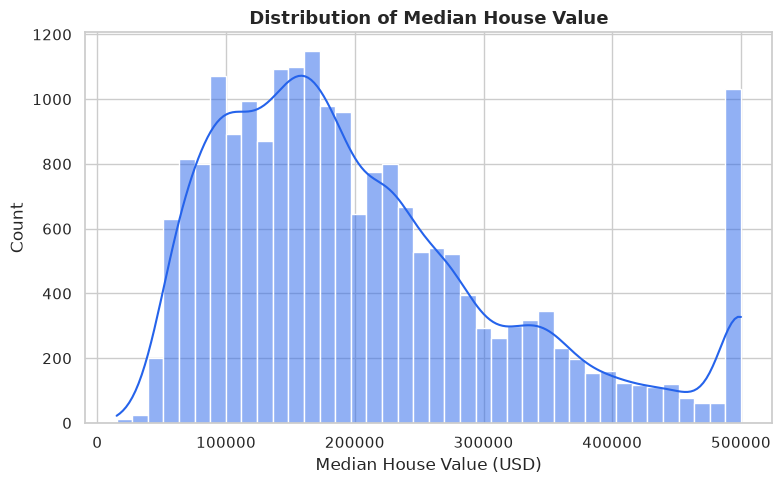

In [6]:
# Target variable distribution
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df[TARGET], bins=40, kde=True, color="#2563eb", ax=ax)
ax.set_title("Distribution of Median House Value", fontsize=13, fontweight="bold")
ax.set_xlabel("Median House Value (USD)")
ax.set_ylabel("Count")
fig.tight_layout()
fig.savefig(out_dir / "01_target_distribution.png", dpi=150)
plt.show()

**Observation:** Most house values lie between `$100,000` and `$265,000`, with a right skew and a noticeable spike at `$500,001` due to the census cap.

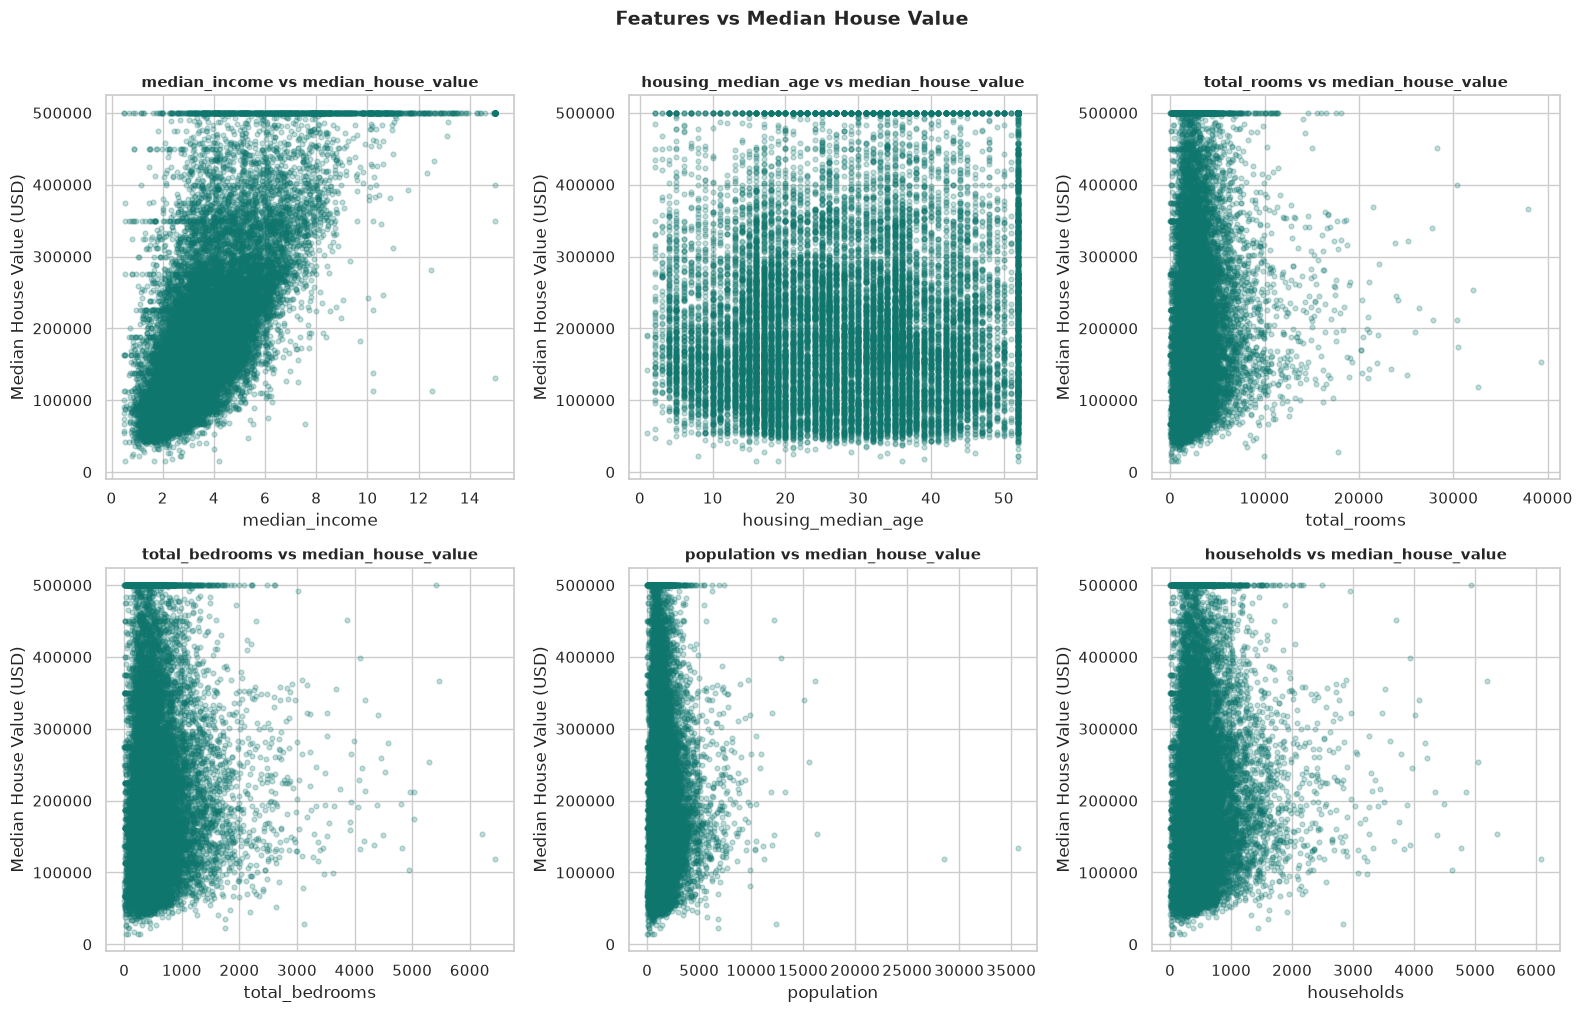

In [7]:
# Scatter plots: each feature vs median_house_value
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, feat in zip(axes.flat, FEATURES):
    ax.scatter(df[feat], df[TARGET], alpha=0.25, s=12, color="#0f766e")
    ax.set_title(f"{feat} vs {TARGET}", fontsize=11, fontweight="bold")
    ax.set_xlabel(feat)
    ax.set_ylabel("Median House Value (USD)")

fig.suptitle("Features vs Median House Value", fontsize=14, fontweight="bold", y=1.01)
fig.tight_layout()
fig.savefig(out_dir / "02_feature_scatter_plots.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** `median_income` clearly has the strongest upward linear pattern with `median_house_value`. The count features (`total_rooms`, `total_bedrooms`, `population`, `households`) are mostly bunched on the left with a few large block-group outliers. The flat line at `500,001` is visible across all plots.

,median_income,housing_median_age,total_rooms,total_bedrooms,population,households,median_house_value
median_income,1.0000,-0.1183,0.1979,-0.0077,0.0051,0.0134,0.6884
housing_median_age,-0.1183,1.0000,-0.3606,-0.3205,-0.2958,-0.3028,0.1064
total_rooms,0.1979,-0.3606,1.0000,0.9304,0.8573,0.9190,0.1333
total_bedrooms,-0.0077,-0.3205,0.9304,1.0000,0.8777,0.9797,0.0497
population,0.0051,-0.2958,0.8573,0.8777,1.0000,0.9072,-0.0253
households,0.0134,-0.3028,0.9190,0.9797,0.9072,1.0000,0.0649
median_house_value,0.6884,0.1064,0.1333,0.0497,-0.0253,0.0649,1.0000


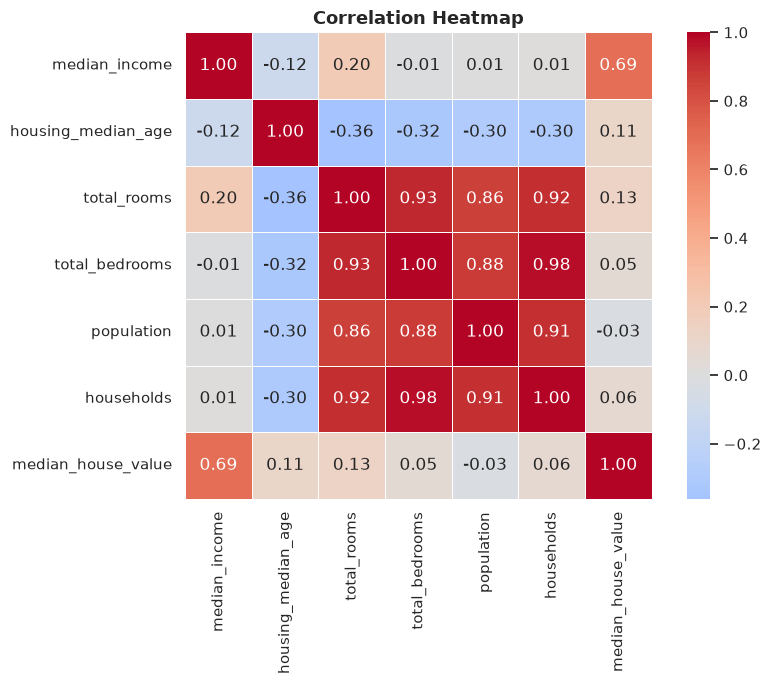

In [8]:
# Correlation matrix and heatmap
corr_matrix = df[FEATURES + [TARGET]].corr()
display(corr_matrix)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation Heatmap", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(out_dir / "03_correlation_heatmap.png", dpi=150)
plt.show()

**Observation:**
- `median_income` has the highest correlation with `median_house_value` ($r = 0.69$), so it is the best choice for the single-feature model.
- Among the input features themselves, `total_bedrooms` & `households` ($0.98$), `total_rooms` & `total_bedrooms` ($0.93$), `total_rooms` & `households` ($0.92$), and `population` & `households` ($0.91$) are very strongly correlated. This is a clear sign of **multicollinearity**.
- Also, a high correlation only shows association—**correlation does not prove causation**.

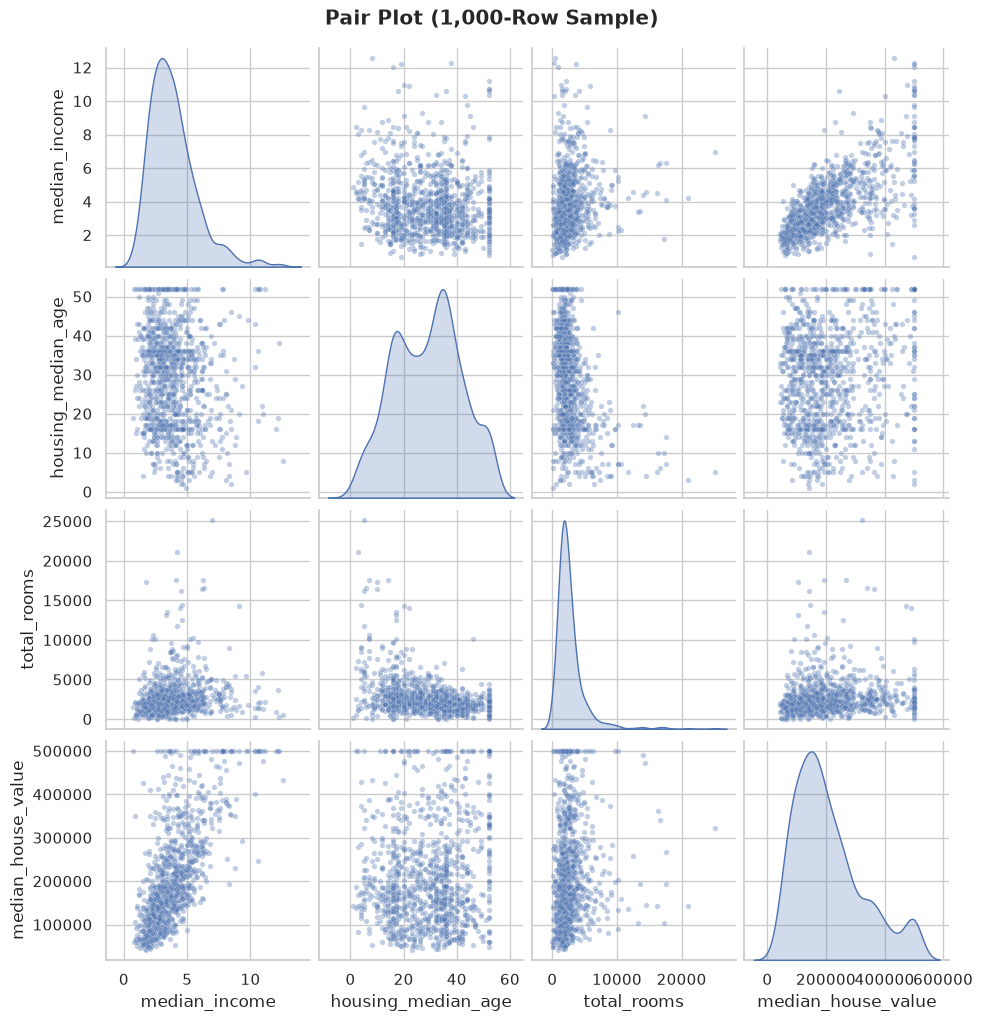

In [9]:
# Pair plot on a 1,000-row sample so it renders cleanly
pair_sample = df[["median_income", "housing_median_age", "total_rooms", TARGET]].sample(
    n=1000, random_state=RANDOM_STATE
)
pair_grid = sns.pairplot(pair_sample, diag_kind="kde", plot_kws={"alpha": 0.35, "s": 15})
pair_grid.fig.suptitle("Pair Plot (1,000-Row Sample)", y=1.02, fontweight="bold")
pair_grid.savefig(out_dir / "04_pair_plot.png", dpi=130, bbox_inches="tight")
plt.show()

**Observation:** `median_income` and `total_rooms` are right-skewed, `housing_median_age` is spread fairly evenly, and `median_income` vs `median_house_value` shows the clearest linear band.

## Step 4: Manual Multiple Linear Regression Calculation

Before using `scikit-learn` on the full dataset, I took a small sample of **6 observations** (rows 0 to 5) and **2 features**:
- $X_1 = \text{median\_income}$
- $X_2 = \text{housing\_median\_age}$
- $y = \text{median\_house\_value}$

Using the Normal Equations:
$$(X^T X)\mathbf{b} = X^T \mathbf{y} \implies \mathbf{b} = (X^T X)^{-1} X^T \mathbf{y}$$

In [10]:
# 6-row sample with 2 features
sample_df = df[["median_income", "housing_median_age", TARGET]].iloc[:6].copy().reset_index(drop=True)
print("Sample Observation Table (n = 6):")
display(sample_df)

x1 = sample_df["median_income"].to_numpy()
x2 = sample_df["housing_median_age"].to_numpy()
y_sample = sample_df[TARGET].to_numpy()

# Design matrix X = [1, x1, x2]
X_design = np.column_stack([np.ones(len(sample_df)), x1, x2])
Xt = X_design.T
XtX = Xt @ X_design
Xty = Xt @ y_sample
det_XtX = np.linalg.det(XtX)
XtX_inv = np.linalg.inv(XtX)
b_manual = XtX_inv @ Xty

np.set_printoptions(precision=4, suppress=True)
print("\nDesign Matrix X (6x3):\n", X_design)
print("\nTarget Vector y (6x1):\n", y_sample)
print("\nX Transpose (X^T) (3x6):\n", Xt)
print("\nX^T X (3x3):\n", XtX)
print(f"\ndet(X^T X) = {det_XtX:,.4f}")
print("\nX^T y (3x1):\n", Xty)
print("\n(X^T X)^(-1):\n", XtX_inv)
print("\nSolved Coefficients [b0, b1, b2]:\n", b_manual)

Sample Observation Table (n = 6):


,median_income,housing_median_age,median_house_value
0,8.3252,41.0000,"452,600.0000"
1,8.3014,21.0000,"358,500.0000"
2,7.2574,52.0000,"352,100.0000"
3,5.6431,52.0000,"341,300.0000"
4,3.8462,52.0000,"342,200.0000"
5,4.0368,52.0000,"269,700.0000"



Design Matrix X (6x3):
 [[ 1.      8.3252 41.    ]
 [ 1.      8.3014 21.    ]
 [ 1.      7.2574 52.    ]
 [ 1.      5.6431 52.    ]
 [ 1.      3.8462 52.    ]
 [ 1.      4.0368 52.    ]]

Target Vector y (6x1):
 [452600. 358500. 352100. 341300. 342200. 269700.]

X Transpose (X^T) (3x6):
 [[ 1.      1.      1.      1.      1.      1.    ]
 [ 8.3252  8.3014  7.2574  5.6431  3.8462  4.0368]
 [41.     21.     52.     52.     52.     52.    ]]

X^T X (3x3):
 [[    6.        37.4101   270.    ]
 [   37.4101   253.8256  1596.4046]
 [  270.      1596.4046 12938.    ]]

det(X^T X) = 51,803.2275

X^T y (3x1):
 [ 2116400.   13630252.59 93960700.  ]

(X^T X)^(-1):
 [[14.1977 -1.0228 -0.1701]
 [-1.0228  0.0913  0.0101]
 [-0.1701  0.0101  0.0024]]

Solved Coefficients [b0, b1, b2]:
 [125635.9161  26774.5776   1336.8329]


In [11]:
# Sample equation, one manual prediction, residual, and Scikit-learn check
b0, b1, b2 = b_manual
print(f"Sample Equation: y_hat = {b0:,.4f} + ({b1:,.4f}) * median_income + ({b2:,.4f}) * housing_median_age")

x1_0, x2_0, y_0 = x1[0], x2[0], y_sample[0]
y_hat_0 = b0 + b1 * x1_0 + b2 * x2_0
residual_0 = y_0 - y_hat_0

print(f"\nManual Prediction for Row 0 (income={x1_0}, age={x2_0}):")
print(f"  y_hat_0 = {b0:,.4f} + ({b1:,.4f} * {x1_0}) + ({b2:,.4f} * {x2_0}) = ${y_hat_0:,.2f}")
print(f"  Actual y_0 = ${y_0:,.2f}")
print(f"  Residual (y_0 - y_hat_0) = ${residual_0:,.2f}")

# Verify with scikit-learn on the same 6 rows
sk_sample = LinearRegression().fit(sample_df[["median_income", "housing_median_age"]], y_sample)
b_sklearn = np.array([sk_sample.intercept_, sk_sample.coef_[0], sk_sample.coef_[1]])

verify_df = pd.DataFrame({
    "Parameter": ["b0 (Intercept)", "b1 (median_income)", "b2 (housing_median_age)"],
    "Manual_Normal_Eq": b_manual,
    "Scikit_Learn": b_sklearn,
    "Abs_Difference": np.abs(b_manual - b_sklearn),
})
print("\nVerification against Scikit-learn:")
display(verify_df)

Sample Equation: y_hat = 125,635.9161 + (26,774.5776) * median_income + (1,336.8329) * housing_median_age

Manual Prediction for Row 0 (income=8.3252, age=41.0):
  y_hat_0 = 125,635.9161 + (26,774.5776 * 8.3252) + (1,336.8329 * 41.0) = $403,349.78
  Actual y_0 = $452,600.00
  Residual (y_0 - y_hat_0) = $49,250.22

Verification against Scikit-learn:


,Parameter,Manual_Normal_Eq,Scikit_Learn,Abs_Difference
0,b0 (Intercept),"125,635.9161","125,635.9161",0.0000
1,b1 (median_income),"26,774.5776","26,774.5776",0.0000
2,b2 (housing_median_age),"1,336.8329","1,336.8329",0.0000


**Observation:** The manual Normal Equations give $b_0 = 125,635.9161$, $b_1 = 26,774.5776$, and $b_2 = 1,336.8329$, which match `scikit-learn` completely (difference is essentially zero).

## Step 5: Train-Test Split

I split the cleaned dataset into **80% training** and **20% testing** using `random_state=42`. All model fitting and scaling are done only on `X_train` and `y_train` so that test data never leaks into training. I also compute a simple **Mean Baseline** (always predicting the training mean).

In [12]:
X = df[FEATURES]
y = df[TARGET].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Total rows   : {len(df)}")
print(f"Training rows: {len(X_train)} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Testing rows : {len(X_test)} ({len(X_test)/len(df)*100:.1f}%)")

y_pred_baseline = np.full(shape=len(y_test), fill_value=y_train.mean(), dtype=float)
print(f"Training Mean Baseline: ${y_train.mean():,.2f}")

Total rows   : 20433
Training rows: 16346 (80.0%)
Testing rows : 4087 (20.0%)
Training Mean Baseline: $206,644.40


## Step 6: Single Linear Regression

Since `median_income` had the strongest correlation with house value ($r = 0.69$), I trained a single-feature Linear Regression model using only `median_income`.

In [13]:
slr_model = LinearRegression()
slr_model.fit(X_train[["median_income"]], y_train)
y_pred_slr = slr_model.predict(X_test[["median_income"]])

print(f"Intercept  : ${slr_model.intercept_:,.2f}")
print(f"Coefficient: ${slr_model.coef_[0]:,.2f} per unit of median_income")
print(f"Test R^2   : {r2_score(y_test, y_pred_slr):.4f}")

Intercept  : $45,035.23
Coefficient: $41,751.96 per unit of median_income
Test R^2   : 0.4720


## Step 7: Multiple Linear Regression

Now I train Multiple Linear Regression using all 6 features on the training set. To compare feature importance fairly across different units (dollars vs years vs room counts), I also fit a `StandardScaler` on `X_train` only and check the standardized coefficients.

In [14]:
mlr_model = LinearRegression()
mlr_model.fit(X_train, y_train)
y_pred_mlr = mlr_model.predict(X_test)

# Standardized coefficients (fit scaler on training data only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
mlr_scaled = LinearRegression().fit(X_train_scaled, y_train)

coef_table = pd.DataFrame({
    "Feature": FEATURES,
    "Unit": [
        "10,000 USD",
        "Years",
        "Rooms",
        "Bedrooms",
        "People",
        "Households",
    ],
    "Raw_Coefficient": mlr_model.coef_,
    "Standardized_Coefficient": mlr_scaled.coef_,
})

print(f"Intercept (b0): ${mlr_model.intercept_:,.2f}")
display(coef_table)

Intercept (b0): $-45,966.35


,Feature,Unit,Raw_Coefficient,Standardized_Coefficient
0,median_income,"10,000 USD","47,698.9661","90,521.5070"
1,housing_median_age,Years,"1,880.9047","23,655.7389"
2,total_rooms,Rooms,-19.8859,"-42,819.1900"
3,total_bedrooms,Bedrooms,104.9803,"43,824.8387"
4,population,People,-33.6260,"-37,975.2267"
5,households,Households,116.3150,"43,965.4287"


### Fitted Multiple Linear Regression Equation

$$\widehat{\text{median\_house\_value}} = -45,966.35 + 47,698.97(\text{median\_income}) + 1,880.90(\text{housing\_median\_age}) - 19.89(\text{total\_rooms}) + 104.98(\text{total\_bedrooms}) - 33.63(\text{population}) + 116.32(\text{households})$$

### What Each Coefficient Means (in Simple Words)
- **Intercept (`-$45,966.35`):** Predicted value when all features are 0. A block group cannot have 0 rooms and 0 households, so the intercept is not meaningful on its own—it just positions the line.
- **`median_income` (`+$47,698.97`):** Keeping other features fixed, every `+$10,000` (1 unit) increase in median income increases predicted house value by about **`$47,699`**.
- **`housing_median_age` (`+$1,880.90`):** Keeping other features fixed, each extra year of median house age adds about **`$1,881`** to the predicted value.
- **`total_rooms` (`-$19.89`):** Keeping bedrooms and households fixed, an extra room lowers predicted value by `$19.89`. This negative sign happens because `total_rooms` is strongly correlated with `total_bedrooms` and `households` (multicollinearity).
- **`total_bedrooms` (`+$104.98`):** Keeping other features fixed, each extra bedroom increases predicted value by **`$104.98`**.
- **`population` (`-$33.63`):** Keeping households and rooms fixed, each extra person lowers predicted value by **`$33.63`** (more crowding per household).
- **`households` (`+$116.32`):** Keeping population and bedrooms fixed, each extra household increases predicted value by **`$116.32`**.
- **Standardized Coefficients:** Comparing the standardized values shows that `median_income` (`+90,521.51`) has by far the largest relative influence on house price. Again, this shows association, not causation.

## Step 8: Model Predictions

Here I predict house prices on the unseen test set (`X_test`), show a sample table of actual vs predicted values, plot Actual vs Predicted, and test one new custom example within the training range.

In [15]:
# Sample of 15 test predictions
pred_df = pd.DataFrame({
    "Actual_Price_USD": y_test[:15],
    "Predicted_Price_USD": y_pred_mlr[:15],
    "Residual_USD": y_test[:15] - y_pred_mlr[:15],
    "Abs_Error_USD": np.abs(y_test[:15] - y_pred_mlr[:15]),
})
display(pred_df)

,Actual_Price_USD,Predicted_Price_USD,Residual_USD,Abs_Error_USD
0,"245,800.0000","165,480.2275","80,319.7725","80,319.7725"
1,"137,900.0000","161,093.7265","-23,193.7265","23,193.7265"
2,"218,200.0000","196,854.0688","21,345.9312","21,345.9312"
3,"220,800.0000","154,256.5417","66,543.4583","66,543.4583"
4,"170,500.0000","199,116.5340","-28,616.5340","28,616.5340"
5,"75,000.0000","131,060.8854","-56,060.8854","56,060.8854"
6,"269,400.0000","257,916.8767","11,483.1233","11,483.1233"
7,"228,900.0000","253,836.8253","-24,936.8253","24,936.8253"
8,"500,001.0000","381,125.0022","118,875.9978","118,875.9978"
9,"80,800.0000","121,476.6725","-40,676.6725","40,676.6725"


**Observation:** Mid-range house predictions are reasonably close, while very expensive or capped (`$500,001`) homes have larger errors because location features (`latitude`, `longitude`, `ocean_proximity`) are not included in this model.

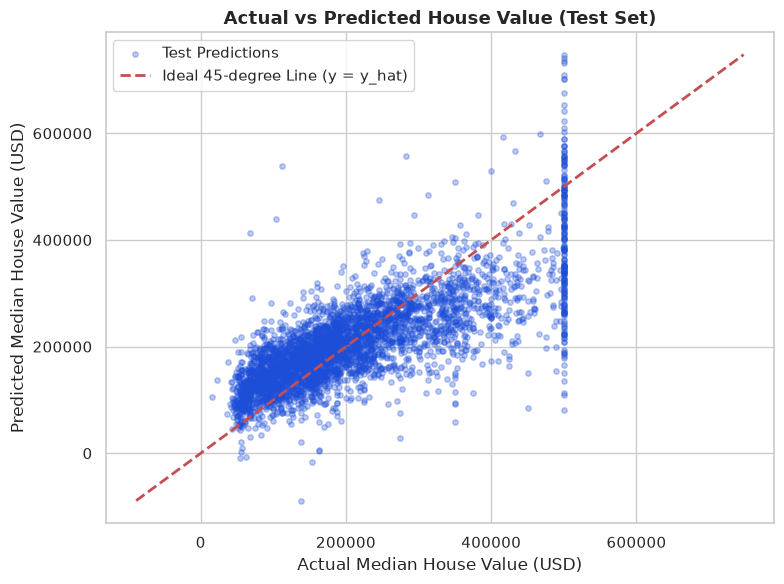

In [16]:
# Actual vs Predicted plot with 45-degree ideal line
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, y_pred_mlr, alpha=0.3, s=15, color="#1d4ed8", label="Test Predictions")
lims = [min(y_test.min(), y_pred_mlr.min()), max(y_test.max(), y_pred_mlr.max())]
ax.plot(lims, lims, "r--", linewidth=2, label="Ideal 45-degree Line (y = y_hat)")
ax.set_title("Actual vs Predicted House Value (Test Set)", fontsize=13, fontweight="bold")
ax.set_xlabel("Actual Median House Value (USD)")
ax.set_ylabel("Predicted Median House Value (USD)")
ax.legend()
fig.tight_layout()
fig.savefig(out_dir / "05_actual_vs_predicted.png", dpi=150)
plt.show()

In [17]:
# One new prediction using reasonable values inside the training range
new_house = pd.DataFrame([{
    "median_income": 4.5,       # $45,000
    "housing_median_age": 25.0, # 25 years
    "total_rooms": 2200.0,
    "total_bedrooms": 420.0,
    "population": 1100.0,
    "households": 400.0,
}])

in_range = ((new_house.iloc[0] >= X_train.min()) & (new_house.iloc[0] <= X_train.max())).all()
new_pred = mlr_model.predict(new_house)[0]

display(new_house)
print(f"Within training range (no extrapolation): {in_range}")
print(f"Predicted Median House Value: ${new_pred:,.2f} USD")

,median_income,housing_median_age,total_rooms,total_bedrooms,population,households
0,4.5000,25.0000,"2,200.0000",420.0000,"1,100.0000",400.0000


Within training range (no extrapolation): True
Predicted Median House Value: $225,581.72 USD


## Step 9: Evaluation Metrics

I calculated **MAE, MSE, RMSE, $R^2$, and Adjusted $R^2$** on the test set and compared all three models.

In [18]:
def evaluate_regression(y_true, y_pred, n_features):
    n = len(y_true)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - n_features - 1)
    return {"MAE (USD)": mae, "MSE": mse, "RMSE (USD)": rmse, "R2": r2, "Adjusted R2": adj_r2}

results_df = pd.DataFrame([
    {"Model": "Mean Baseline", **evaluate_regression(y_test, y_pred_baseline, 1)},
    {"Model": "Single Linear Regression (median_income)", **evaluate_regression(y_test, y_pred_slr, 1)},
    {"Model": "Multiple Linear Regression (6 features)", **evaluate_regression(y_test, y_pred_mlr, len(FEATURES))},
])
display(results_df)

,Model,MAE (USD),MSE,RMSE (USD),R2,Adjusted R2
0,Mean Baseline,"92,836.5012","13,676,390,692.8183","116,946.1017",-0.0001,-0.0003
1,Single Linear Regression (median_income),"63,374.5513","7,221,011,204.2350","84,976.5333",0.4720,0.4718
2,Multiple Linear Regression (6 features),"56,642.4993","5,865,619,646.9593","76,587.3335",0.5711,0.5704


### Understanding the Metrics
- **MAE (`$56,642.50`):** Average absolute error—on average, predictions are off by about `$56,643`.
- **MSE (`5.87e9`):** Average squared error, which penalizes large mistakes much more heavily.
- **RMSE (`$76,587.33`):** Square root of MSE, in **USD**. Because RMSE (`$76,587`) is larger than MAE (`$56,643`), there are some large errors on expensive homes.
- **$R^2$ (`0.5711`):** The 6-feature model explains **57.11%** of the variance in unseen test house prices (compared to ~0% for the Mean Baseline).
- **Adjusted $R^2$ (`0.5704`):** Penalizes extra features that do not add real value. Since it is almost equal to $R^2$, the extra features are genuinely helping.

### Did Extra Features Improve the Model?
Yes. Moving from Single Linear Regression (`median_income` only) to Multiple Linear Regression increased **Test $R^2$ from `0.4720` to `0.5711`** and lowered **RMSE from `$84,977` to `$76,587`** (`$8,390` improvement).

## Step 10: Residual Analysis

Residuals are `Actual - Predicted`. Checking them shows where the linear model works well and where it struggles.

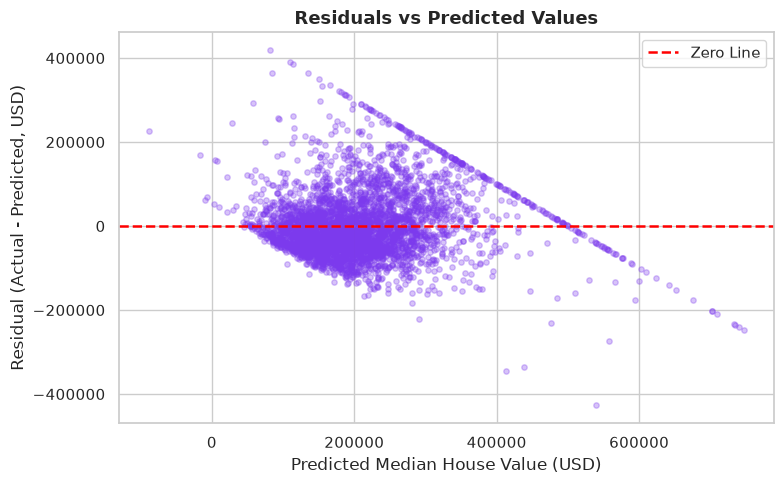

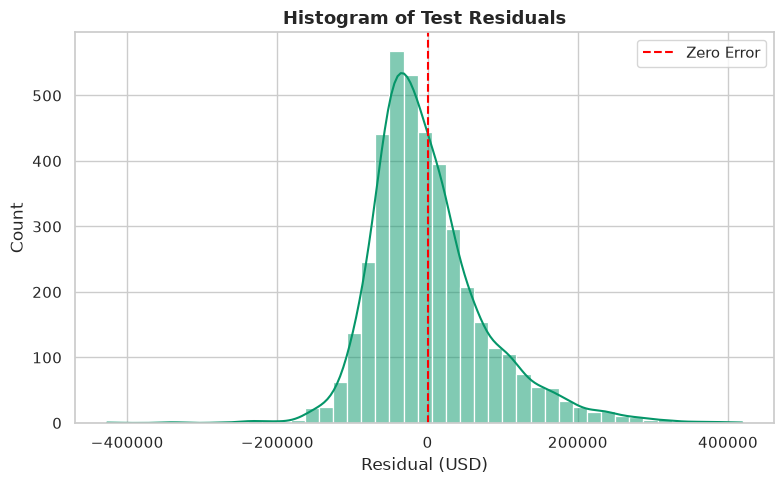

In [19]:
residuals = y_test - y_pred_mlr

# Residuals vs Predicted
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(y_pred_mlr, residuals, alpha=0.3, s=15, color="#7c3aed")
ax.axhline(0, color="red", linestyle="--", linewidth=1.8, label="Zero Line")
ax.set_title("Residuals vs Predicted Values", fontsize=13, fontweight="bold")
ax.set_xlabel("Predicted Median House Value (USD)")
ax.set_ylabel("Residual (Actual - Predicted, USD)")
ax.legend()
fig.tight_layout()
fig.savefig(out_dir / "06_residuals_vs_predicted.png", dpi=150)
plt.show()

# Residual Histogram
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(residuals, bins=45, kde=True, color="#059669", ax=ax)
ax.axvline(0, color="red", linestyle="--", linewidth=1.5, label="Zero Error")
ax.set_title("Histogram of Test Residuals", fontsize=13, fontweight="bold")
ax.set_xlabel("Residual (USD)")
ax.set_ylabel("Count")
ax.legend()
fig.tight_layout()
fig.savefig(out_dir / "07_residual_histogram.png", dpi=150)
plt.show()

**Observations:**
- **Residuals vs Predicted:** The spread gets wider as predicted price increases (slight funnel shape = heteroscedasticity). There is also a diagonal cut at the top caused by the `$500,001` census cap.
- **Residual Histogram:** Roughly centered around `0`, but skewed slightly to the right (some actual prices are much higher than what the linear model predicts).
- **Actual vs Predicted (Step 8):** Follows the 45-degree line fairly well in the middle (`$100k–$300k`), but underpredicts high-end/capped homes.

## Step 11: Multicollinearity

To check if input features are redundant, I examined the feature correlation matrix and computed the **Variance Inflation Factor (VIF)** on `X_train`.

In [20]:
display(X_train.corr())

X_train_const = sm.add_constant(X_train)
vif_df = pd.DataFrame({
    "Feature": X_train.columns,
    "VIF": [variance_inflation_factor(X_train_const.values, i) for i in range(1, X_train_const.shape[1])],
}).sort_values("VIF", ascending=False).reset_index(drop=True)

display(vif_df)

,median_income,housing_median_age,total_rooms,total_bedrooms,population,households
median_income,1.0000,-0.1206,0.2021,-0.0054,0.0072,0.0166
housing_median_age,-0.1206,1.0000,-0.3597,-0.3191,-0.2917,-0.3018
total_rooms,0.2021,-0.3597,1.0000,0.9291,0.8517,0.9168
total_bedrooms,-0.0054,-0.3191,0.9291,1.0000,0.8722,0.9786
population,0.0072,-0.2917,0.8517,0.8722,1.0000,0.9031
households,0.0166,-0.3018,0.9168,0.9786,0.9031,1.0000


,Feature,VIF
0,total_bedrooms,33.9848
1,households,31.9919
2,total_rooms,11.6941
3,population,5.9632
4,median_income,1.5148
5,housing_median_age,1.1601


**VIF Interpretation & Fixes:**
- Usually **VIF > 5** means moderate multicollinearity and **VIF > 10** means severe multicollinearity.
- `total_bedrooms` (`33.98`), `households` (`31.99`), and `total_rooms` (`11.69`) have **severe multicollinearity**, and `population` (`5.96`) is also high, because larger block groups have more of all four counts together. Only `median_income` (`1.51`) and `housing_median_age` (`1.16`) are low.
- **How to fix this:**
  1. Combine raw counts into ratios like `rooms_per_household`, `bedrooms_per_room`, and `population_per_household`.
  2. Drop overlapping count columns (e.g., keep `households` and drop `total_bedrooms`).
  3. Apply **Ridge Regression** to stabilize the coefficients.

## Step 12: Linear Regression Assumptions

| Assumption | What It Means | Status for This Dataset |
| :--- | :--- | :--- |
| **Linearity** | $X$ and $y$ have a linear relationship. | **Partially Reasonable:** `median_income` is fairly linear with price, but count features and capped prices are not. |
| **Independence of Errors** | Residuals are independent of each other. | **Doubtful:** Nearby California neighborhoods share location effects not included in our 6 features. |
| **Homoscedasticity** | Residual variance stays constant. | **Doubtful:** Error spread widens at higher predicted prices and hits the `$500,001` cap. |
| **Normality of Residuals** | Residuals follow an approximate bell curve. | **Mostly Reasonable:** Centered near 0, though slightly right-skewed. |
| **No Severe Multicollinearity** | Input features are not heavily redundant. | **Violated:** `total_bedrooms`, `households`, and `total_rooms` all have VIF > 10. |

## Step 13: Final Conclusion

- **Dataset & Features:** California Housing dataset (`20,433` cleaned rows), using 6 numerical features (`median_income`, `housing_median_age`, `total_rooms`, `total_bedrooms`, `population`, `households`) to predict `median_house_value`.
- **Performance:** Multiple Linear Regression reached **Test $R^2 = 0.5711$**, **Adjusted $R^2 = 0.5704$**, **MAE = `$56,642.50`**, and **RMSE = `$76,587.33`**, clearly beating both the Mean Baseline ($R^2 = 0.000$) and Single Linear Regression ($R^2 = 0.4720$).
- **Key Takeaways:**
  - `median_income` is by far the strongest predictor of house value.
  - Features can overlap in the information they carry (high VIF on room/bedroom/household counts), and simply adding more features does not always improve coefficient stability.
  - A linear model misses non-linear patterns and important missing factors like exact location (`latitude`, `longitude`, `ocean_proximity`).
- **Limitations:** Prices are from 1990 and capped at `$500,001`. Predictions are estimates, not guarantees, and should **not** be used for real property appraisals or mortgage decisions.
- **Future Work:** Create per-household ratio features to reduce VIF, include location features, and test tree-based models like Random Forest.